# Budgeted prediction-market event screening

This notebook runs the submitted Dome study: data preparation, chronological opportunity prediction, economic replay and reporting. N=3 is primary; N=5 is secondary. Opportunity labels and value targets are independent of execution P&L.

The default verifies saved preprocessing and fitted checkpoints, reproduces their scores, reconciles economic accounting and regenerates all analyses and the report. Set `FULL_RERUN=True` to rebuild raw books, retune/refit every weekly model and rerun execution into a new directory. This can take substantially longer; CUDA is optional.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if not (ROOT/'FYP').is_dir():
    raise RuntimeError('Run the notebook with the submission directory as the working directory')
sys.path.insert(0,str(ROOT))
FULL_RERUN=False
DEVICE=None  # 'cpu', 'cuda', or None for automatic selection

## 1. Frozen data and definitions

Inspect the raw inventory and supported baskets. One candidate is an event, not a token or a guaranteed trade. Full-window unknown outcomes retain missing targets.

In [2]:
import json
import pandas as pd
from IPython.display import display, Image
from FYP.data.pipeline import load, plans
raw=pd.read_csv(ROOT/'inputs/raw_inventory.csv',dtype={'token_id':str})
display(raw[['event_slug','token_id','first','last']].head())
display(pd.Series([p['stratum'] for p in plans()]).value_counts().rename('supported_events').to_frame())

,event_slug,token_id,first,last
0,1-searched-person-on-google-this-year,1082944184701543310123155764189258968225550889...,2025-10-14 19:55:22.539000+00:00,2025-12-04 07:30:38.028000+00:00
1,1-searched-person-on-google-this-year,4793269844871547190601025477822734255907377069...,2025-10-14 20:07:55.941000+00:00,2025-12-04 07:18:22.251000+00:00
2,1-searched-person-on-google-this-year,6986426429804926805842787812966629516294627880...,2025-10-14 19:44:24.582000+00:00,2025-12-03 20:31:41.369000+00:00
3,1-searched-person-on-google-this-year,1150943260133758742956443689955761493969658031...,2025-10-14 20:07:52.969000+00:00,2025-12-04 02:26:44.045000+00:00
4,1-searched-person-on-google-this-year,9296964715296744107192707267620058790425231751...,2025-10-14 19:45:21.078000+00:00,2025-12-04 05:14:09.506000+00:00


,supported_events
negrisk,46
ladder,5


## 2. Execute the research workflow

The runner performs chronological safeguards, prediction reproduction, economic reconciliation and the 28 tests before exporting CSV tables, 50 figures and the dissertation PDF. In full mode it first reconstructs features/labels from raw depth, performs earlier-only tuning and weekly refits, and runs persistent event ledgers. Supplied results are preserved.

In [3]:
from FYP.experiments.runner import execute
RUN=execute(full=FULL_RERUN,device=DEVICE)
ARTIFACTS=RUN/'artifacts'
TABLES=ARTIFACTS/'tables'
display(pd.read_json(ARTIFACTS/'verification.json',typ='series').to_frame('value'))

Checking actual model populations and reproducing saved scores...


.

.

.

.

.

... (24 outputs left out)

Exported 72 tables and 50 figures.


Built dissertation: 24 main-text pages; 175 abstract words.


Research outputs: C:\Users\Daron\coding\inefficiency-prediction\submission


,value
weekly_fits_checked,199
scores_reproduced,True
folds,13
summary_rows,3612
attempt_rows,94237
economic_accounting_reconciled,True
tests_run,28
failures,0
errors,0
token_mappings,994


## 3. Opportunity prediction

Value capture weights each known hour by its peak displayed basket margin. It is not cumulative tradable profit. All eligible candidates compete before their labels are consulted.

In [4]:
display(pd.read_csv(TABLES/'population.csv'))
primary=pd.read_csv(TABLES/'primary_prediction.csv')
display(primary[['model','captured_positive_windows','recall','peak_value_recall','precision_known','selected_unknown_fraction']])

,scheduled_hours,event_hours,events,known,unknown,positive,positive_events,median_candidates,maximum_candidates,competitive_hours_n3,total_peak_value
0,2024,19766,44,15787,3979,359,12,9.0,19,1887,8838.30667


,model,captured_positive_windows,recall,peak_value_recall,precision_known,selected_unknown_fraction
0,fixed_book_random_forest,340,0.947075,0.995271,0.067891,0.161560
1,fixed_combined_random_forest,333,0.927577,0.994094,0.069332,0.195881
2,fixed_combined_logistic,331,0.922006,0.991950,0.062689,0.116022
3,classifier_rank_ensemble,334,0.930362,0.991558,0.067652,0.173447
4,tuned_combined_logistic,334,0.930362,0.990640,0.063126,0.114180
5,tabm_two_stage,316,0.880223,0.990429,0.059021,0.103633
6,fixed_book_logistic,329,0.916435,0.988062,0.062417,0.117529
7,fixed_combined_xgboost,321,0.894150,0.987453,0.068327,0.213461
8,value_rank_ensemble,315,0.877437,0.985846,0.060472,0.127909
9,forest_two_stage,315,0.877437,0.985745,0.066950,0.212289


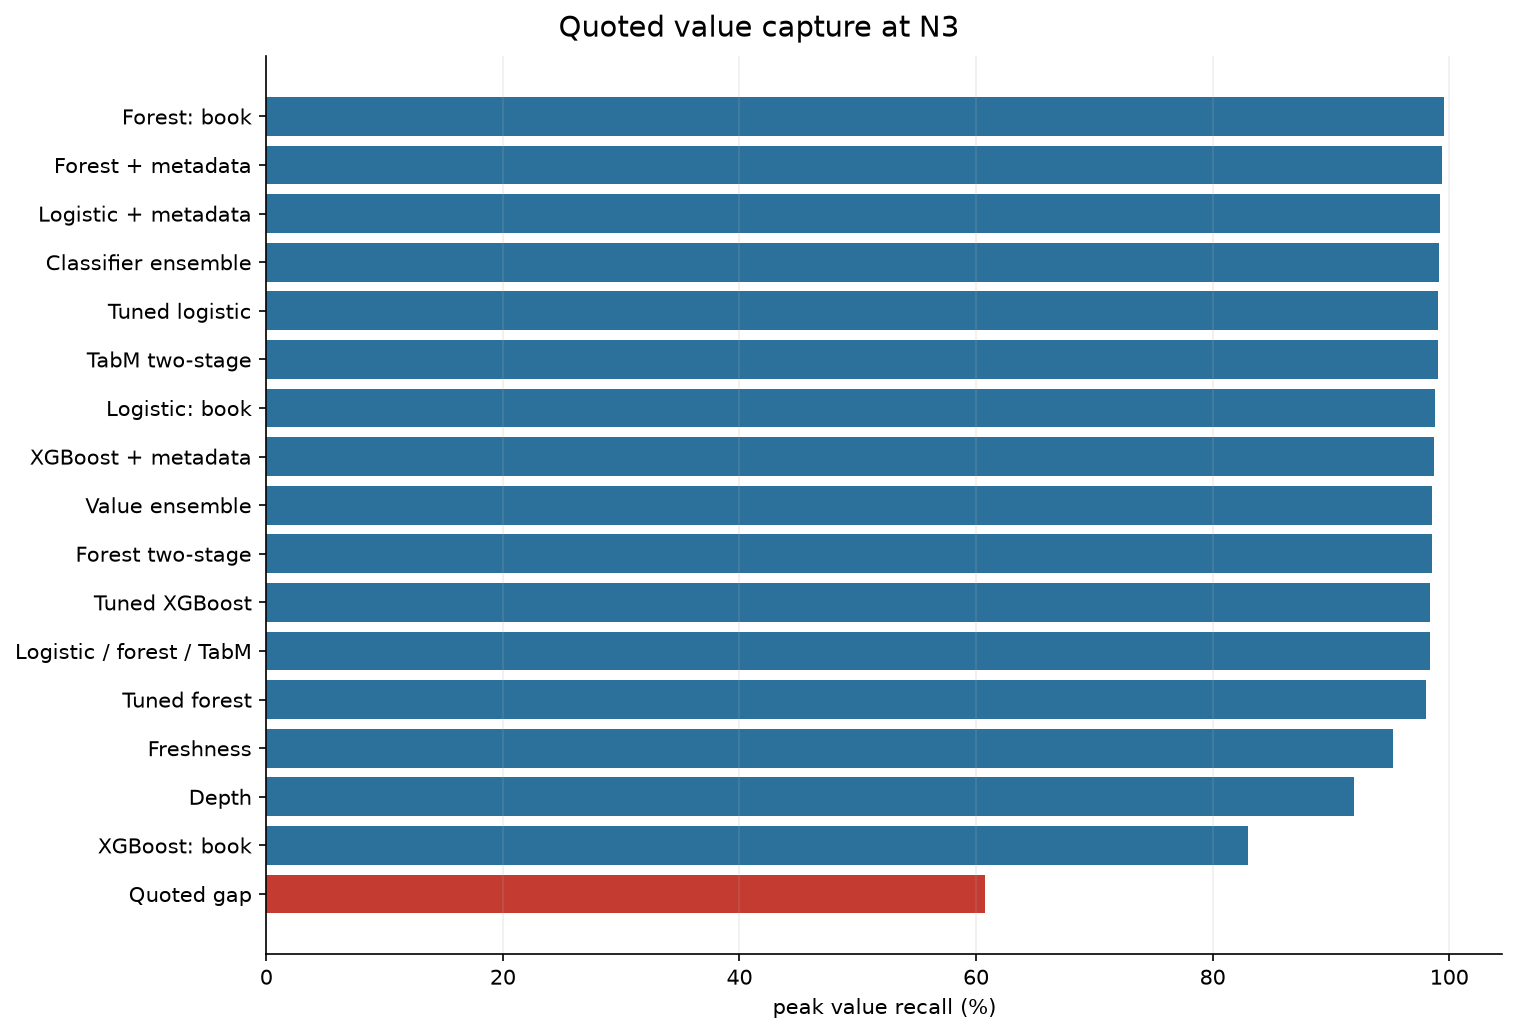

Same eligible forward pool. Known-outcome metrics exclude unknown labels; ranking does not.


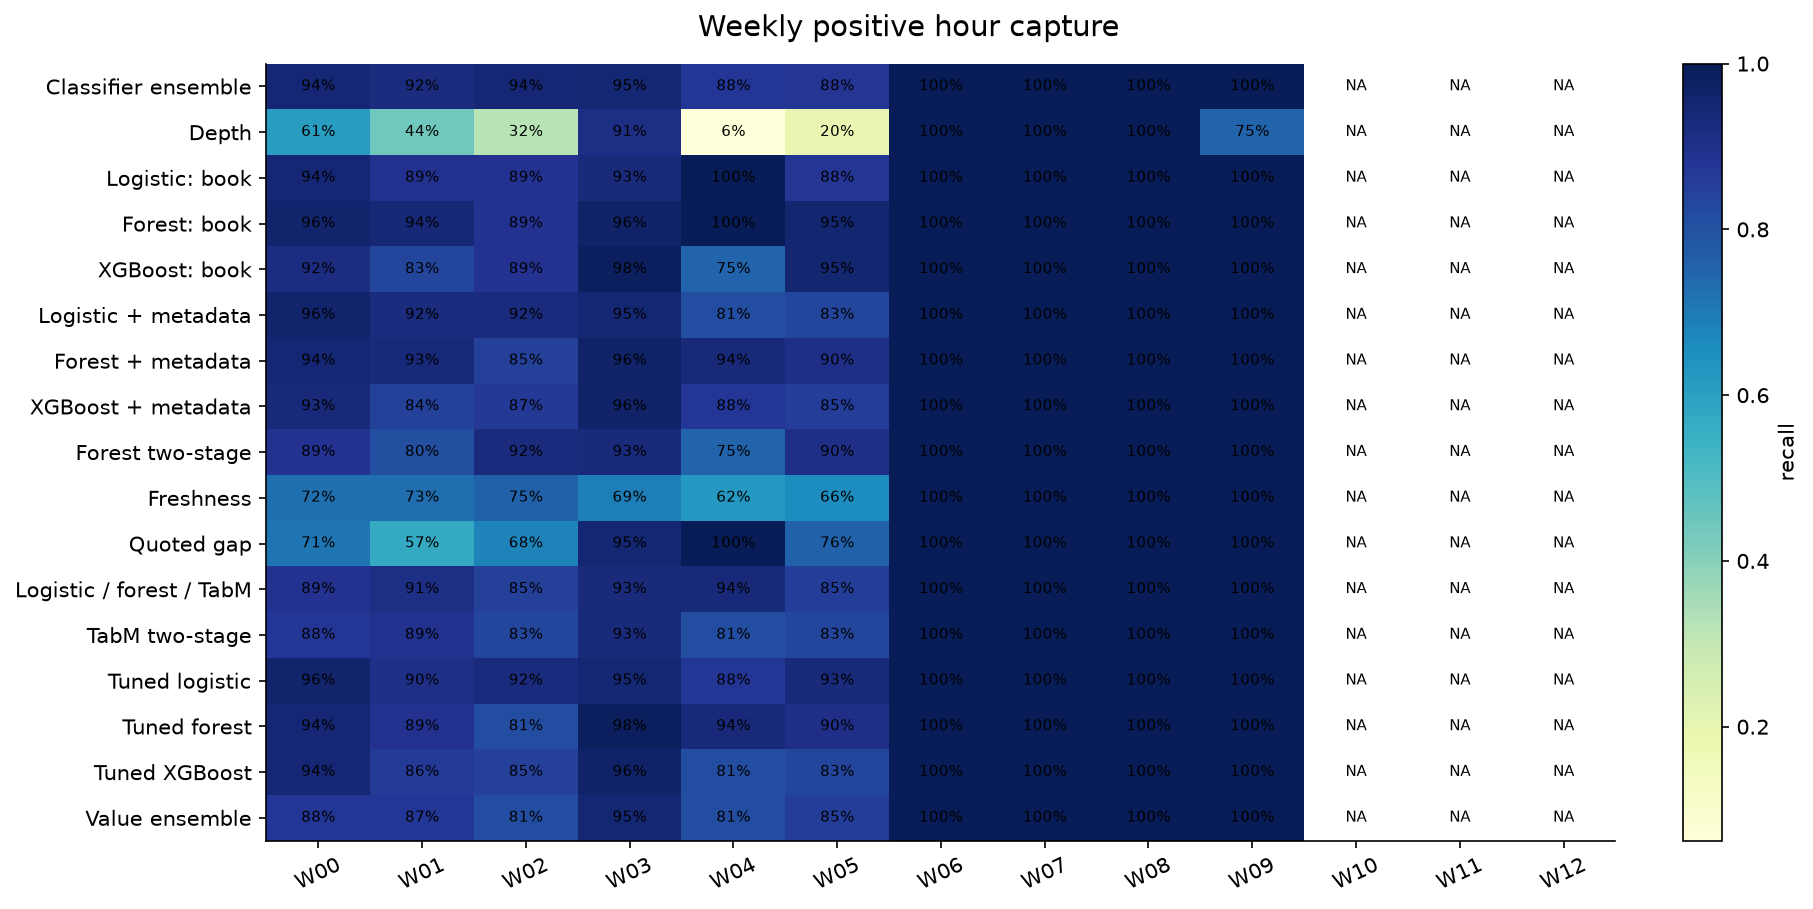

NA means no known positive target in that week.


In [5]:
catalog=pd.read_csv(ARTIFACTS/'figure_index.csv').set_index('number')
def figure(number):
    row=catalog.loc[number]
    display(Image(filename=str(ARTIFACTS/row.file),width=1000))
    print(row.caption)
figure(17)
figure(26)

## 4. Features, tuning and ensembles

Fixed book-only/combined comparisons isolate metadata with identical family settings. The inner search uses earlier chronological blocks and the same N=3 value objective across families.

,method,book_recall,combined_recall,recall_change,book_value_capture,combined_value_capture,value_change
0,logistic,0.916435,0.922006,0.005571,0.988062,0.991950,0.003888
1,random_forest,0.947075,0.927577,-0.019499,0.995271,0.994094,-0.001176
2,xgboost,0.899721,0.894150,-0.005571,0.829814,0.987453,0.157639


,origin,method,candidate,params,tuned_before,epochs
0,week_00,logistic,6,"{""C"": 0.1, ""penalty"": ""l2"", ""class_weight"": nu...",2025-11-11 00:00:00+00:00,NaN
1,week_00,random_forest,2,"{""n_estimators"": 200, ""max_depth"": 8, ""min_sam...",2025-11-11 00:00:00+00:00,NaN
2,week_00,xgboost,1,"{""n_estimators"": 200, ""learning_rate"": 0.05, ""...",2025-11-11 00:00:00+00:00,NaN
3,week_00,tabm_two_stage,0,"{""n_blocks"": 2, ""d_block"": 128, ""dropout"": 0.1...",2025-11-11 00:00:00+00:00,"{""classifier"": 38, ""amount"": 21}"
4,week_04,logistic,7,"{""C"": 1.0, ""penalty"": ""l2"", ""class_weight"": nu...",2025-12-09 00:00:00+00:00,NaN
5,week_04,random_forest,0,"{""n_estimators"": 200, ""max_depth"": 10, ""min_sa...",2025-12-09 00:00:00+00:00,NaN
6,week_04,xgboost,5,"{""n_estimators"": 400, ""learning_rate"": 0.03, ""...",2025-12-09 00:00:00+00:00,NaN
7,week_04,tabm_two_stage,2,"{""n_blocks"": 2, ""d_block"": 64, ""dropout"": 0.1,...",2025-12-09 00:00:00+00:00,"{""classifier"": 57, ""amount"": 31}"
8,week_08,logistic,7,"{""C"": 1.0, ""penalty"": ""l2"", ""class_weight"": nu...",2026-01-06 00:00:00+00:00,NaN
9,week_08,random_forest,0,"{""n_estimators"": 200, ""max_depth"": 10, ""min_sa...",2026-01-06 00:00:00+00:00,NaN


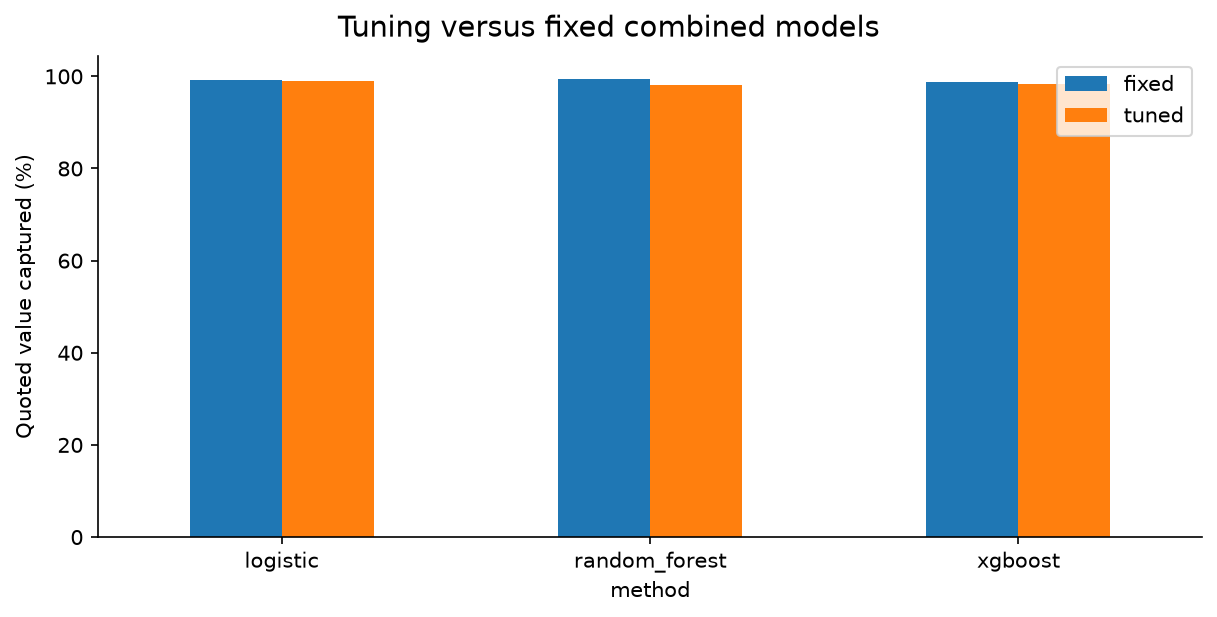

Outer forward performance, N=3; hyperparameters selected using earlier inner blocks.


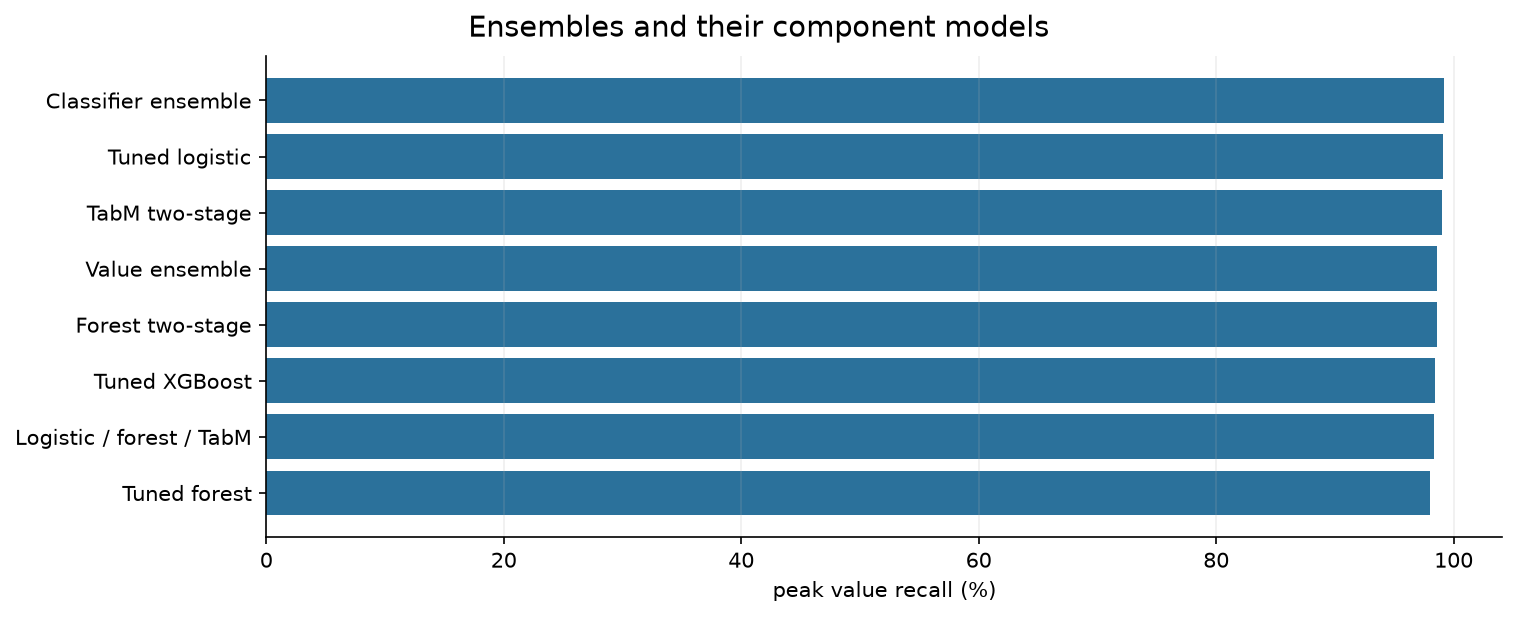

Equal within-scan percentile-rank averages; N=3.


In [6]:
display(pd.read_csv(TABLES/'metadata_comparison.csv'))
display(pd.read_csv(TABLES/'selected_hyperparameters.csv'))
figure(31)
figure(32)

## 5. Economic replay

The primary scenario uses 100 ms total source-update-to-arrival delay, uncapped funding/shares, recorded depth, independent per-leg FOK support and a one-second partial unwind. There is no imposed random failure chance. This layer evaluates fixed monitoring choices; execution P&L is not a training target.

,model,known_pnl_usd,attempts,completed,partial_pnl_usd,unknown_attempts,max_drawdown_usd,no_settlement_funding_usd
0,classifier_rank_ensemble,5902.49610,462,445,-416.75787,0,205.91262,1.430530e+06
70,depth_rule,5745.85229,285,280,-286.67424,0,207.40862,1.355759e+06
140,fixed_book_logistic,5878.46544,438,420,-417.02187,0,206.19862,1.422656e+06
210,fixed_book_random_forest,5873.31925,453,436,-416.75787,0,206.15062,1.426124e+06
280,fixed_book_xgboost,5187.45418,454,437,-380.32105,0,205.96062,1.355160e+06
350,fixed_combined_logistic,5892.81347,434,416,-417.02187,0,206.19862,1.419071e+06
420,fixed_combined_random_forest,5873.60247,456,439,-416.75787,0,206.15062,1.431301e+06
490,fixed_combined_xgboost,5915.38270,449,433,-380.05705,0,205.96062,1.448101e+06
560,forest_two_stage,5921.18455,454,439,-377.97627,0,206.15062,1.442267e+06
630,freshness_rule,5778.39834,400,384,-414.67709,0,206.15062,1.384801e+06


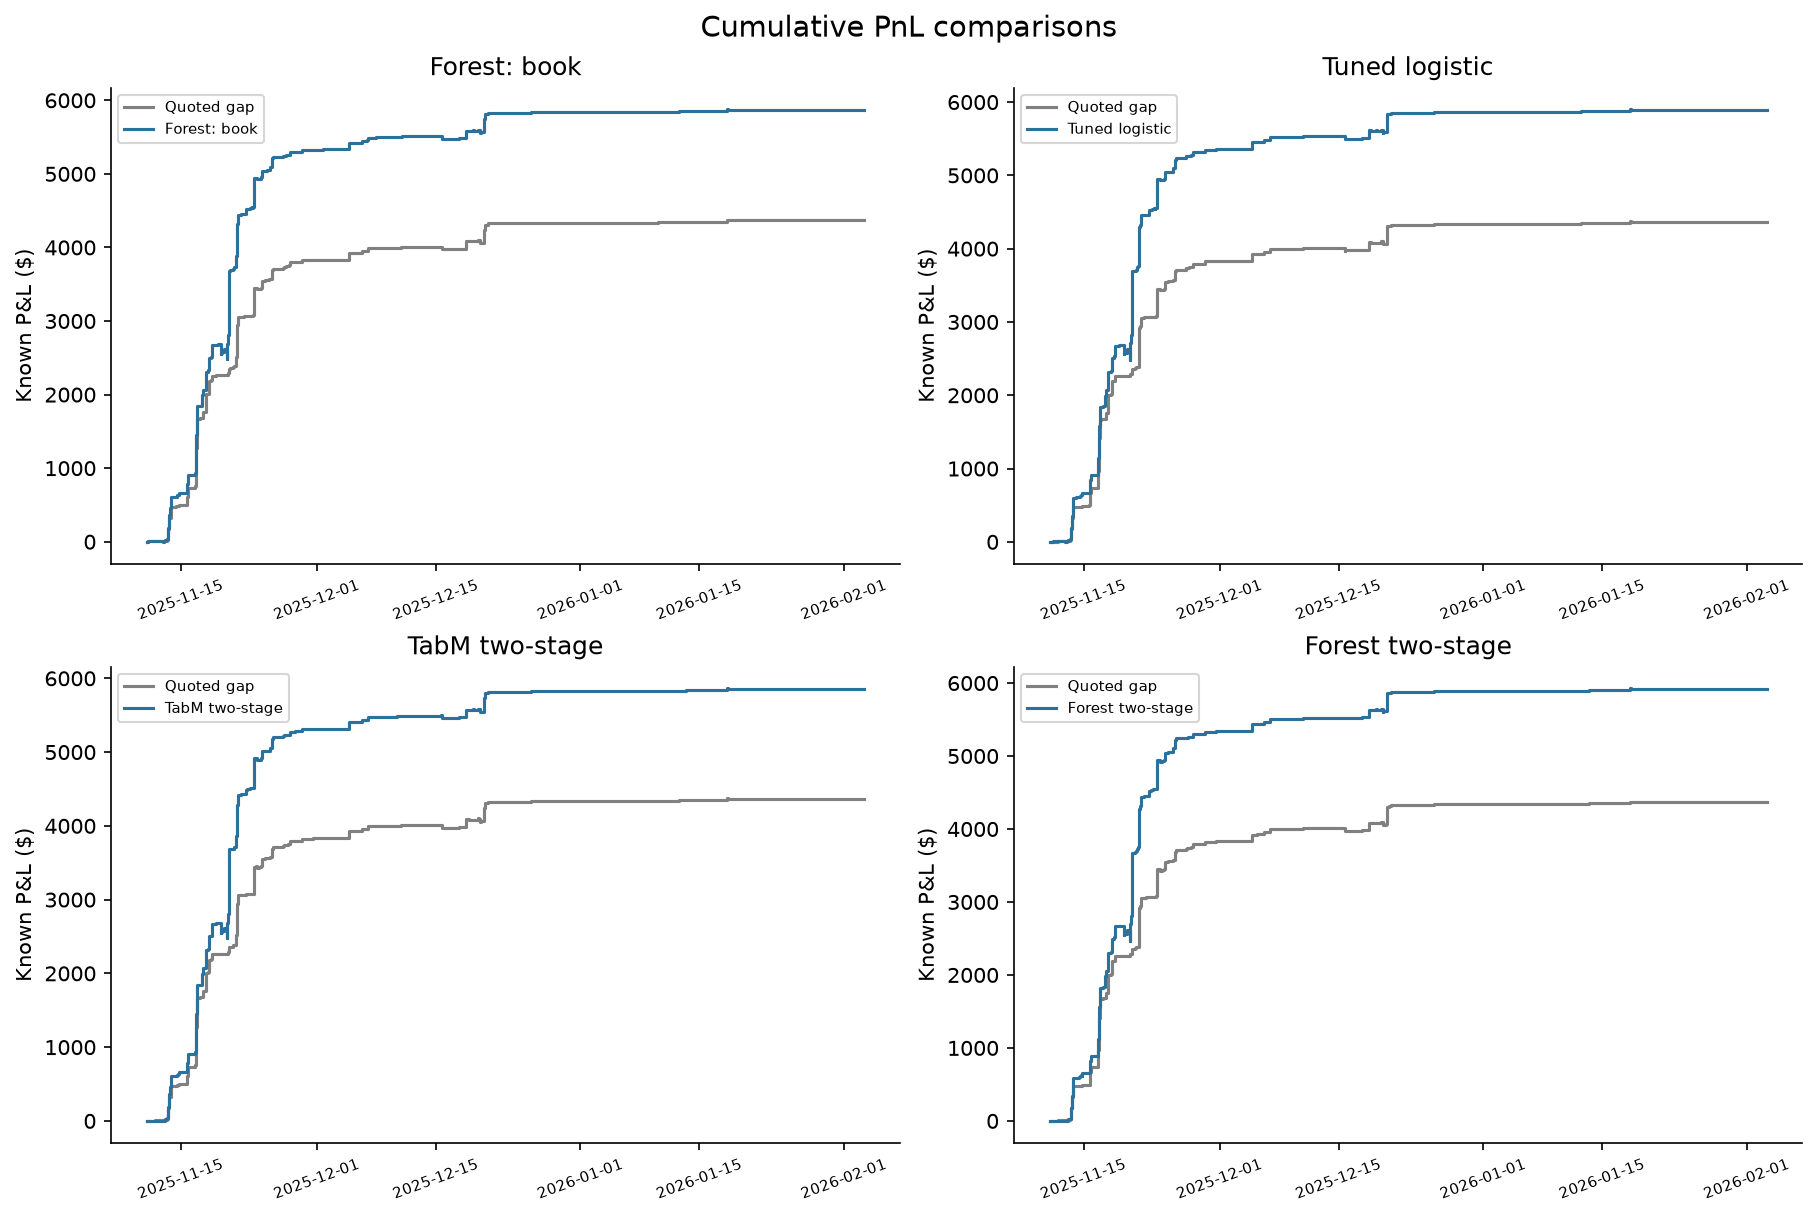

N=3, 100 ms; separate panels and a common quoted-gap reference avoid crowded lines.


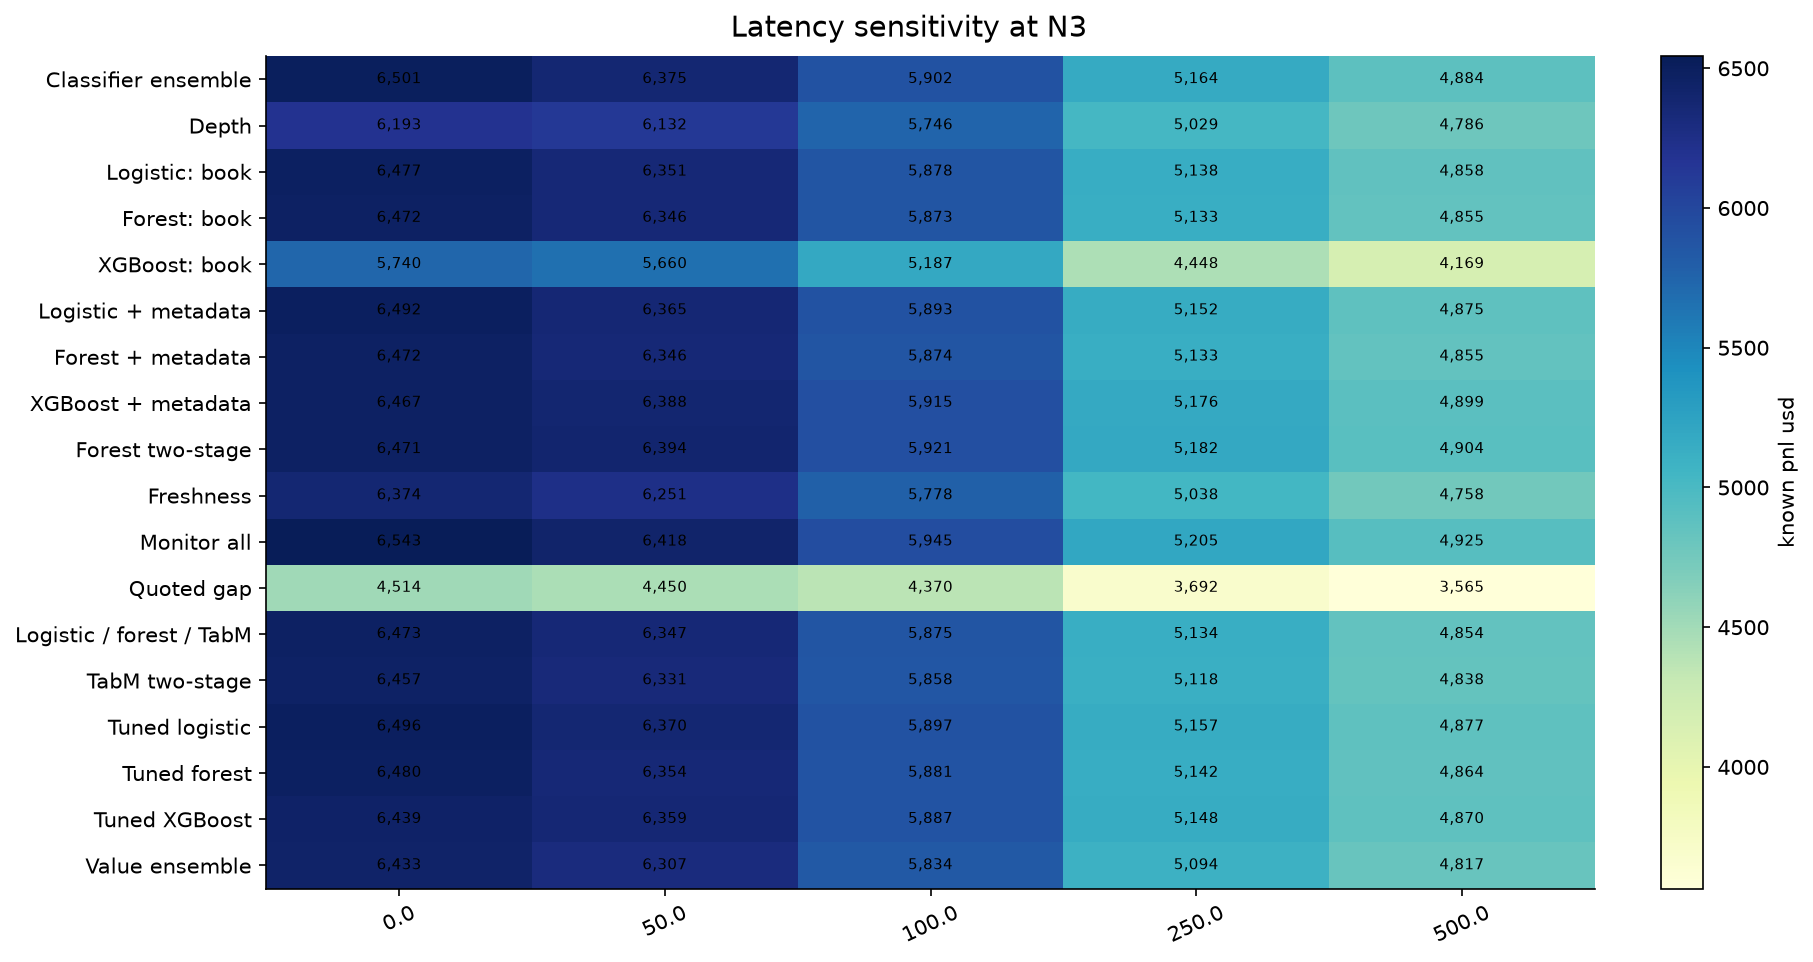

Fixed first-layer selections; separate persistent ledgers for 0/50/100/250/500 ms. Dollars.


In [7]:
economics=pd.read_csv(TABLES/'economic_summary.csv')
main=economics.loc[economics.scope.eq('all_events')&economics.fold.eq('all')&economics.top_n.eq(3)&economics.arrival_delay_s.eq(.1)]
display(main[['model','known_pnl_usd','attempts','completed','partial_pnl_usd','unknown_attempts','max_drawdown_usd','no_settlement_funding_usd']])
figure(43)
figure(41)

## 6. Concentration and limitations

December Fed dominates quoted target value. Removing the event and reranking is material to the economic interpretation. Missing evidence, frozen retrospective membership, source-time alignment and assumed fills constrain generalisation.

,model,known_pnl_usd,attempts,unknown_attempts
3080,classifier_rank_ensemble,731.94676,276,0
3094,depth_rule,555.52738,94,0
3108,fixed_book_logistic,697.08369,245,0
3122,fixed_book_random_forest,730.52105,283,0
3136,fixed_book_xgboost,771.20141,271,0
3150,fixed_combined_logistic,696.05723,238,0
3164,fixed_combined_random_forest,727.34044,281,0
3178,fixed_combined_xgboost,771.14521,270,0
3192,forest_two_stage,756.47500,270,0
3206,freshness_rule,630.50467,212,0


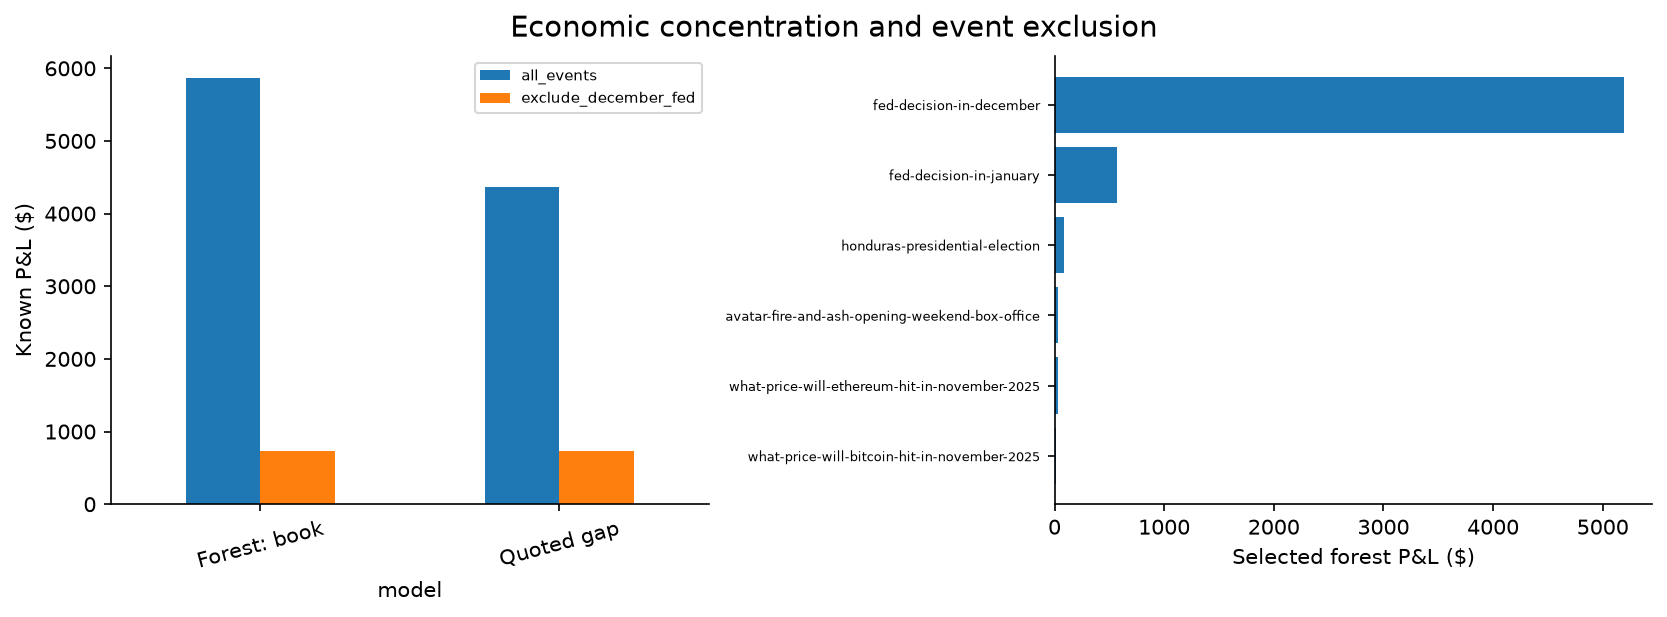

Exclusion reranks the pool. The leading event materially changes the economic interpretation.


,model,seven_day_blocks,recall_difference,recall_lower95,recall_upper95,recall_defined_draws,value_capture_difference,value_capture_lower95,value_capture_upper95,value_capture_defined_draws
0,classifier_rank_ensemble,13,0.194986,0.038959,0.286885,10000,0.383979,0.019054,0.598275,10000
1,depth_rule,13,-0.228412,-0.439796,-0.108107,10000,0.311630,-0.302141,0.555528,10000
2,fixed_book_logistic,13,0.181058,0.039383,0.265310,10000,0.380483,0.024064,0.597796,10000
3,fixed_book_random_forest,13,0.211699,0.071036,0.302961,10000,0.387692,0.023267,0.600594,10000
4,fixed_book_xgboost,13,0.164345,0.044301,0.226054,10000,0.222235,0.015773,0.308458,10000
5,fixed_combined_logistic,13,0.186630,0.016391,0.282724,10000,0.384371,0.021312,0.598995,10000
6,fixed_combined_random_forest,13,0.192201,0.050208,0.287569,10000,0.386515,0.022069,0.599997,10000
7,fixed_combined_xgboost,13,0.158774,0.034327,0.227361,10000,0.379874,0.009115,0.593469,10000
8,forest_two_stage,13,0.142061,0.016446,0.207695,10000,0.378166,0.014028,0.588352,10000
9,freshness_rule,13,-0.008357,-0.174178,0.097266,10000,0.344508,-0.115935,0.576088,10000


In [8]:
excluded=economics.loc[economics.scope.eq('exclude_december_fed')&economics.fold.eq('all')&economics.top_n.eq(3)&economics.arrival_delay_s.eq(.1)]
display(excluded[['model','known_pnl_usd','attempts','unknown_attempts']])
figure(49)
display(pd.read_csv(TABLES/'paired_capture_intervals.csv'))

## 7. Deliverable indexes

Every catalogued figure has a CSV data table. The report volume includes selected evidence; the full catalog remains separately inspectable.

In [9]:
display(pd.read_csv(ARTIFACTS/'table_index.csv'))
display(pd.read_csv(ARTIFACTS/'figure_index.csv'))
print('Report:',RUN/'report/dissertation.pdf')
print('Editable report:',RUN/'report/dissertation.md')

,file,rows
0,tables/all_prediction_metrics.csv,952
1,tables/economic_summary.csv,3612
2,tables/event_capture.csv,748
3,tables/event_pnl.csv,3284
4,tables/figure_01.csv,5
...,...,...
67,tables/secondary_prediction.csv,17
68,tables/selected_hyperparameters.csv,12
69,tables/training_populations.csv,13
70,tables/tuning_search.csv,168


,number,title,file,source_table,caption
0,1,Research pipeline,figures/01_research_pipeline.png,tables/figure_01.csv,Opportunity targets and tuning are independent...
1,2,Chronological expanding histories,figures/02_chronological_expanding_histories.png,tables/figure_02.csv,Full target windows are purged before each ori...
2,3,Supported and evaluated cohort,figures/03_supported_and_evaluated_cohort.png,tables/figure_03.csv,Supported membership differs from time-specifi...
3,4,Event observation extents,figures/04_event_observation_extents.png,tables/figure_04.csv,"Endpoints are descriptive offline extents, not..."
4,5,Hourly candidate competition,figures/05_hourly_candidate_competition.png,tables/figure_05.csv,Candidate counts use the complete eligible poo...
5,6,Weekly monitoring competition,figures/06_weekly_monitoring_competition.png,tables/figure_06.csv,A budget has no exclusion effect when the pool...
6,7,Outcome coverage over time,figures/07_outcome_coverage_over_time.png,tables/figure_07.csv,Unknown intervals do not become negative examp...
7,8,Opportunity prevalence over time,figures/08_opportunity_prevalence_over_time.png,tables/figure_08.csv,Undefined when no known outcomes exist.
8,9,Outcomes by structural event type,figures/09_outcomes_by_structural_event_type.png,tables/figure_09.csv,The much smaller ladder cohort limits comparis...
9,10,Quoted gap at ranking,figures/10_quoted_gap_at_ranking.png,tables/figure_10.csv,"All eligible forward event-hours, before monit..."


Report: C:\Users\Daron\coding\inefficiency-prediction\submission\report\dissertation.pdf
Editable report: C:\Users\Daron\coding\inefficiency-prediction\submission\report\dissertation.md
